# 8. From symbols to numbers: `lambdify`, SciPy and code generation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/08_symbols_to_numbers.ipynb)

A formula is rarely the end of an engineering calculation. You still need numbers, plots, fits
to data, and often a simulation. The productive pattern is:

> **derive with SymPy → convert with `lambdify` → compute with NumPy and SciPy**

SymPy does the algebra and calculus once, without mistakes. NumPy and SciPy then do the
arithmetic millions of times, fast.

**Worked examples:** fitting an adsorption isotherm with an exact Jacobian, the period of a
large-amplitude pendulum, optimization with exact derivatives, and exporting formulas to C,
Fortran, MATLAB and LaTeX.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit, minimize

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 8.1 Why not just use `subs`?

`expr.subs(x, value).evalf()` works, but it re-walks the symbolic expression for every value.
`lambdify` translates the expression into an ordinary NumPy function once.

In [2]:
x = sp.symbols("x")
expr = sp.series(sp.exp(sp.sin(x)), x, 0, 12).removeO()      # a moderately long polynomial
grid = np.linspace(0, 1, 200)

start = time.perf_counter()
slow = [expr.subs(x, value).evalf() for value in grid]
t_subs = time.perf_counter() - start

f = sp.lambdify(x, expr, "numpy")
start = time.perf_counter()
fast = f(grid)
t_lambdify = time.perf_counter() - start

assert np.allclose(np.array(slow, dtype=float), fast)
print(f"subs + evalf: {t_subs * 1e3:.1f} ms    lambdify: {t_lambdify * 1e3:.3f} ms    "
      f"speed-up: about {t_subs / t_lambdify:,.0f} times")

subs + evalf: 386.6 ms    lambdify: 0.223 ms    speed-up: about 1,732 times


The exact ratio depends on your computer, but it is typically a factor of several hundred or more.
Use `subs` for a handful of values and `lambdify` for everything else.

## 8.2 How `lambdify` works

It writes Python source code for you. You can read it:

In [3]:
import inspect

g = sp.lambdify(x, sp.sin(x) ** 2 + sp.exp(-x), "numpy")
print(inspect.getsource(g))

def _lambdifygenerated(x):
    return sin(x)**2 + exp(-x)



Things worth knowing:

- The first argument fixes the **order of the arguments** of the new function.
- A list of expressions gives a function that returns a list.
- `"numpy"` covers elementary functions. Use `"scipy"` when the expression contains special
  functions such as Bessel or error functions.

In [4]:
r, z = sp.symbols("r z")
field = sp.lambdify((r, z), [r * sp.exp(-z), sp.sqrt(r**2 + z**2)], "numpy")
print(field(np.array([1.0, 2.0]), 0.5))

bessel = sp.lambdify(x, sp.besselj(0, x), "scipy")       # J0 appears in heat conduction in cylinders
print(bessel(np.array([0.0, 1.0, 2.4048])))              # 2.4048 is its first zero

[array([0.60653066, 1.21306132]), array([1.11803399, 2.06155281])]
[1.00000000e+00 7.65197687e-01 1.32682843e-05]


## 8.3 Fitting a model to data with an exact Jacobian

**Problem.** Adsorption data (amount adsorbed $q$ against pressure $p$) are to be fitted with the
Langmuir isotherm

$$q = \frac{q_{max} K p}{1 + K p}.$$

`scipy.optimize.curve_fit` works better when it is given the derivatives of the model with
respect to the parameters. Deriving them by hand invites errors; SymPy does not make them.

In [5]:
p, q_max, K = sp.symbols("p q_max K", positive=True)
langmuir = q_max * K * p / (1 + K * p)

sensitivities = [sp.simplify(sp.diff(langmuir, par)) for par in (q_max, K)]
sensitivities

⎡  K⋅p      p⋅qₘₐₓ  ⎤
⎢───────, ──────────⎥
⎢K⋅p + 1           2⎥
⎣         (K⋅p + 1) ⎦

In [6]:
model = sp.lambdify((p, q_max, K), langmuir, "numpy")
model_jac = sp.lambdify((p, q_max, K), sensitivities, "numpy")

def jacobian(p_data, *params):
    return np.column_stack(model_jac(p_data, *params))

# synthetic "measurements": true values q_max = 2.5 mol/kg, K = 0.8 1/bar, plus noise
rng = np.random.default_rng(seed=3)
p_data = np.array([0.1, 0.2, 0.5, 1, 2, 4, 6, 8, 10.0])
q_data = model(p_data, 2.5, 0.8) + rng.normal(0, 0.04, p_data.size)

best, covariance = curve_fit(model, p_data, q_data, p0=[1, 1], jac=jacobian)
errors = np.sqrt(np.diag(covariance))
print(f"q_max = {best[0]:.2f} ± {errors[0]:.2f} mol/kg     K = {best[1]:.2f} ± {errors[1]:.2f} 1/bar")
assert abs(best[0] - 2.5) < 3 * errors[0] and abs(best[1] - 0.8) < 3 * errors[1]

q_max = 2.46 ± 0.05 mol/kg     K = 0.80 ± 0.06 1/bar


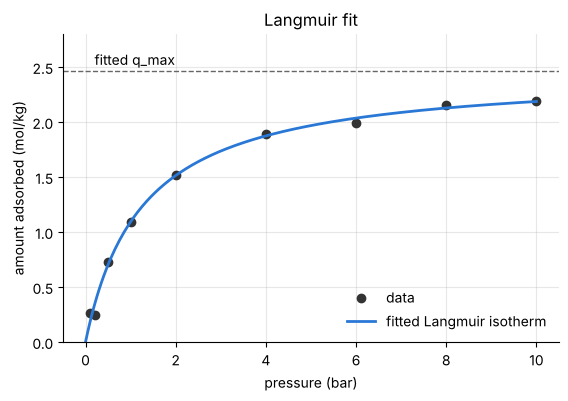

In [7]:
p_grid = np.linspace(0, 10, 200)
fig, ax = plt.subplots()
ax.plot(p_data, q_data, "o", color="0.2", ms=6, label="data")
ax.plot(p_grid, model(p_grid, *best), label="fitted Langmuir isotherm")
ax.axhline(best[0], color="0.4", lw=1, ls="--")
ax.annotate("fitted q_max", xy=(0.2, best[0]), xytext=(0.2, best[0] + 0.06))
ax.set(xlabel="pressure (bar)", ylabel="amount adsorbed (mol/kg)", ylim=(0, 2.8), title="Langmuir fit")
ax.legend(frameon=False, loc="lower right");

The fit recovers the true parameters within the reported uncertainties.

## 8.4 A differential equation with no elementary solution

**Problem.** The pendulum equation $\ddot\theta = -\sin\theta$ (time in units of $\sqrt{L/g}$) is
usually linearized to $\ddot\theta = -\theta$, giving a period of $2\pi$ for every amplitude.
How wrong is that for large swings?

Write the model symbolically, convert it to a first-order system, and pass it to `solve_ivp`.
SymPy can also supply the Jacobian. Implicit solvers such as `Radau` and `BDF` accept it
through `jac=` for stiff problems; this problem is not stiff, so it is shown but not used.

In [8]:
theta, omega = sp.symbols("theta omega")
state = sp.Matrix([theta, omega])
rhs = sp.Matrix([omega, -sp.sin(theta)])          # d(theta)/dt, d(omega)/dt

rhs_fun = sp.lambdify((theta, omega), list(rhs), "numpy")
jac_fun = sp.lambdify((theta, omega), rhs.jacobian(state), "numpy")
rhs.jacobian(state)

⎡   0     1⎤
⎢          ⎥
⎣-cos(θ)  0⎦

In [9]:
def period(amplitude_deg):
    """Period of the pendulum released from rest at the given amplitude."""
    def upward_crossing(_, y):          # the pendulum passes through theta = 0 moving forwards
        return y[0]
    upward_crossing.direction = 1
    sol = solve_ivp(lambda _, y: rhs_fun(*y), [0, 60], [np.radians(amplitude_deg), 0.0],
                    events=upward_crossing, rtol=1e-10, atol=1e-12)
    return np.diff(sol.t_events[0])[0]

amplitudes = np.array([5, 30, 60, 90, 120, 150, 170])
numeric = np.array([period(a) for a in amplitudes])

**Verify.** There *is* an exact answer, in terms of a special function that SymPy knows: the
complete elliptic integral, $T = 4\,K\!\left(\sin^2(\theta_0/2)\right)$.

`lambdify` does not have a translation for every special function. `elliptic_k` is one it
misses, so supply the SciPy equivalent yourself in a dictionary.

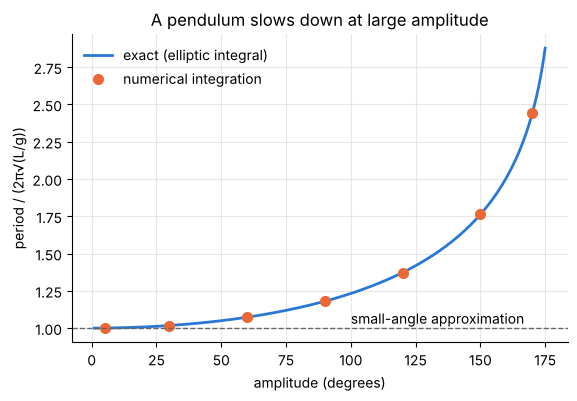

In [10]:
from scipy.special import ellipk

theta0 = sp.symbols("theta_0", positive=True)
exact_period = sp.lambdify(theta0, 4 * sp.elliptic_k(sp.sin(theta0 / 2) ** 2),
                           modules=[{"elliptic_k": ellipk}, "numpy"])
exact = exact_period(np.radians(amplitudes))
assert np.allclose(numeric, exact, rtol=1e-7)

fine = np.linspace(1, 175, 200)
fig, ax = plt.subplots()
ax.plot(fine, exact_period(np.radians(fine)) / (2 * np.pi), label="exact (elliptic integral)")
ax.plot(amplitudes, numeric / (2 * np.pi), "o", color="#eb6834", ms=7, label="numerical integration")
ax.axhline(1, color="0.4", lw=1, ls="--")
ax.annotate("small-angle approximation", xy=(100, 1), xytext=(100, 1.03))
ax.set(xlabel="amplitude (degrees)", ylabel="period / (2π√(L/g))", title="A pendulum slows down at large amplitude")
ax.legend(frameon=False, loc="upper left");

At 90° the period is 18 % longer than the small-angle value.

## 8.5 Optimization with exact gradients and Hessians

Optimizers converge faster and more accurately when they are given derivatives. The Rosenbrock
function, a standard test with a curved narrow valley and its minimum at $(1, 1)$, shows the difference.

In [11]:
x1, x2 = sp.symbols("x_1 x_2")
rosenbrock = (1 - x1) ** 2 + 100 * (x2 - x1**2) ** 2

gradient = [sp.diff(rosenbrock, v) for v in (x1, x2)]
hessian = sp.hessian(rosenbrock, (x1, x2))
gradient, hessian

⎛                                                        ⎡       2             ↪
⎜⎡         ⎛    2     ⎞                     2         ⎤  ⎢1200⋅x₁  - 400⋅x₂ +  ↪
⎜⎣- 400⋅x₁⋅⎝- x₁  + x₂⎠ + 2⋅x₁ - 2, - 200⋅x₁  + 200⋅x₂⎦, ⎢                     ↪
⎝                                                        ⎣       -400⋅x₁       ↪

↪           ⎤⎞
↪ 2  -400⋅x₁⎥⎟
↪           ⎥⎟
↪      200  ⎦⎠

In [12]:
fun = sp.lambdify([(x1, x2)], rosenbrock, "numpy")
grad = sp.lambdify([(x1, x2)], gradient, "numpy")
hess = sp.lambdify([(x1, x2)], hessian, "numpy")

start_point = [-1.2, 1.0]
no_derivatives = minimize(fun, start_point, method="Nelder-Mead")
with_derivatives = minimize(fun, start_point, method="trust-exact",
                            jac=lambda v: np.array(grad(v)), hess=lambda v: np.array(hess(v)))

for name, res in (("no derivatives (Nelder-Mead)", no_derivatives), ("exact gradient and Hessian", with_derivatives)):
    print(f"{name:30s} function calls: {res.nfev:4d}    error in the minimum: {np.abs(res.x - 1).max():.1e}")
assert with_derivatives.nfev < no_derivatives.nfev

no derivatives (Nelder-Mead)   function calls:  159    error in the minimum: 4.2e-05
exact gradient and Hessian     function calls:   26    error in the minimum: 1.1e-09


Far fewer evaluations of the function, and several more correct digits. (Each iteration also
evaluates the gradient and Hessian, which cost little here because they are exact formulas.)

## 8.6 Exporting formulas to other languages

Formulas derived here can be pasted into a C or Fortran simulation code, a MATLAB script or a
report. Common subexpression elimination (`cse`) first finds repeated pieces so they are
computed once.

In [13]:
xs, ys = sp.symbols("x y", positive=True)
potential = sp.sqrt(xs**2 + ys**2) * sp.exp(-sp.sqrt(xs**2 + ys**2)) + 1 / sp.sqrt(xs**2 + ys**2)

sp.cse(potential)        # (list of shared pieces, expression written with them)

⎛⎡⎛       _________⎞⎤                ⎞
⎜⎢⎜      ╱  2    2 ⎟⎥  ⎡    -x₀   1 ⎤⎟
⎜⎣⎝x₀, ╲╱  x  + y  ⎠⎦, ⎢x₀⋅ℯ    + ──⎥⎟
⎝                      ⎣          x₀⎦⎠

In [14]:
print("C:      ", sp.ccode(potential))
print("Fortran:", sp.fcode(potential, source_format="free", standard=95))
print("MATLAB: ", sp.octave_code(potential))
print("Julia:  ", sp.julia_code(potential))
print("Python: ", sp.pycode(potential))
print("LaTeX:  ", sp.latex(potential))

C:       sqrt(pow(x, 2) + pow(y, 2))*exp(-sqrt(pow(x, 2) + pow(y, 2))) + pow(pow(x, 2) + pow(y, 2), -1.0/2.0)
Fortran: sqrt(x**2 + y**2)*exp(-sqrt(x**2 + y**2)) + 1/sqrt(x**2 + y**2)
MATLAB:  sqrt(x.^2 + y.^2).*exp(-sqrt(x.^2 + y.^2)) + 1./sqrt(x.^2 + y.^2)
Julia:   sqrt(x .^ 2 + y .^ 2) .* exp(-sqrt(x .^ 2 + y .^ 2)) + 1 ./ sqrt(x .^ 2 + y .^ 2)
Python:  math.sqrt(x**2 + y**2)*math.exp(-math.sqrt(x**2 + y**2)) + 1/math.sqrt(x**2 + y**2)
LaTeX:   \sqrt{x^{2} + y^{2}} e^{- \sqrt{x^{2} + y^{2}}} + \frac{1}{\sqrt{x^{2} + y^{2}}}


Note the element-wise operators (`.^`, `.*`, `./`) in the MATLAB output: the generated code
works on arrays.

## Summary: which tool for which job

| Job | Tool |
| --- | --- |
| a few values, or many digits | `expr.subs(...).evalf(n)` |
| arrays, plots, loops | `sp.lambdify(args, expr, "numpy")` |
| special functions | `sp.lambdify(..., "scipy")` |
| fitting | `lambdify` the model and its parameter derivatives → `curve_fit` |
| ODEs without closed form | `lambdify` the right-hand side and Jacobian → `solve_ivp` |
| optimization | `lambdify` the gradient and Hessian → `minimize` |
| another language | `ccode`, `fcode`, `octave_code`, `julia_code`, `latex` |

## Exercises

1. Fit the same data with the Freundlich isotherm $q = k\,p^{1/n}$, using a SymPy-derived
   Jacobian. Which model fits better, judged by the sum of squared residuals?
2. Add linear damping, $\ddot\theta = -\sin\theta - c\,\dot\theta$, and plot the motion for
   $c = 0.2$ from an initial angle of 170°.
3. The Antoine equation is $\log_{10} P = A - B/(C + T)$. Derive $dP/dT$ symbolically, then
   use `lambdify` to plot it for water ($A = 8.07131$, $B = 1730.63$, $C = 233.426$; $P$ in mmHg,
   $T$ in °C) between 1 and 100 °C.
4. Generate C code for the van der Waals pressure and its two partial derivatives using `cse`
   to share common subexpressions.